### EXPERIMENT 1: 2D DISCRETE FOURIER TRANSFORM

Objective: Implement the 2D DFT and compare it with NumPy's FFT.

Tasks:
 1. Compute the DFT of a small binary image manually.
 2. Compare the result with np.fft.fft2().
 3. Recover the original image using the inverse FFT.

Question: What does the DC component F(0,0) represent?

Manual DFT:
 [[ 9.   +0.j    -3.927-2.853j -0.573-1.763j -0.573+1.763j -3.927+2.853j]
 [-3.927-2.853j  0.809+2.49j  -0.309+0.951j  0.809-0.588j  2.618+0.j   ]
 [-0.573-1.763j -0.309+0.951j -0.309+0.225j  0.382+0.j     0.809+0.588j]
 [-0.573+1.763j  0.809-0.588j  0.382+0.j    -0.309-0.225j -0.309-0.951j]
 [-3.927+2.853j  2.618+0.j     0.809+0.588j -0.309-0.951j  0.809-2.49j ]]

NumPy FFT:
 [[ 9.   +0.j    -3.927-2.853j -0.573-1.763j -0.573+1.763j -3.927+2.853j]
 [-3.927-2.853j  0.809+2.49j  -0.309+0.951j  0.809-0.588j  2.618-0.j   ]
 [-0.573-1.763j -0.309+0.951j -0.309+0.225j  0.382+0.j     0.809+0.588j]
 [-0.573+1.763j  0.809-0.588j  0.382-0.j    -0.309-0.225j -0.309-0.951j]
 [-3.927+2.853j  2.618+0.j     0.809+0.588j -0.309-0.951j  0.809-2.49j ]]

Results match: True
DC component: (9+0j)
Reconstruction error: 8.881784197001253e-17


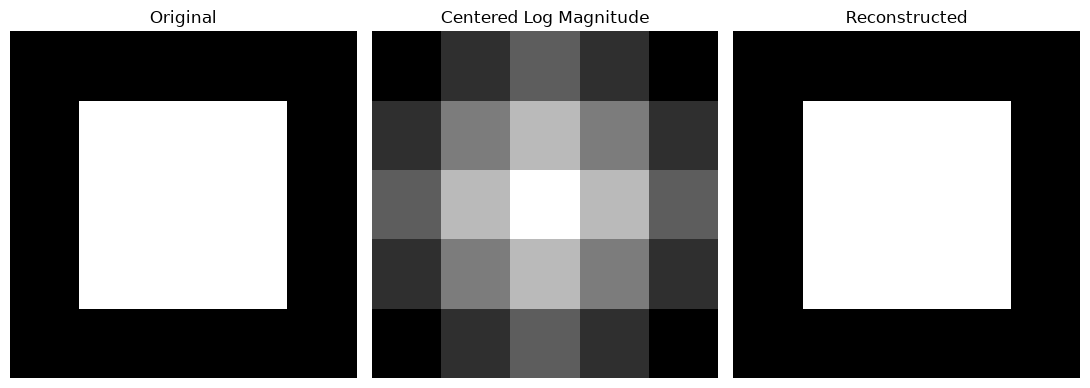

In [1]:
import numpy as np
import matplotlib.pyplot as plt

img = np.array([
    [0, 0, 0, 0, 0],
    [0, 1, 1, 1, 0],
    [0, 1, 1, 1, 0],
    [0, 1, 1, 1, 0],
    [0, 0, 0, 0, 0]
], dtype=float)

M, N = img.shape
F_manual = np.zeros((M, N), dtype=complex)

for u in range(M):
    for v in range(N):
        for x in range(M):
            for y in range(N):
                F_manual[u, v] += img[x, y] * np.exp(
                    -2j * np.pi * (u*x/M + v*y/N)
                )

F_numpy = np.fft.fft2(img)
reconstructed = np.fft.ifft2(F_numpy).real

print("Manual DFT:\n", np.round(F_manual, 3))
print("\nNumPy FFT:\n", np.round(F_numpy, 3))
print("\nResults match:", np.allclose(F_manual, F_numpy))
print("DC component:", F_numpy[0, 0])
print("Reconstruction error:", np.max(np.abs(img - reconstructed)))

fig, axes = plt.subplots(1, 3, figsize=(11, 4))

for ax, image, title in zip(
    axes,
    [img, np.log1p(np.abs(np.fft.fftshift(F_numpy))), reconstructed],
    ["Original", "Centered Log Magnitude", "Reconstructed"]
):
    ax.imshow(image, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 2: FOURIER MAGNITUDE AND PHASE

Objective: Investigate the roles of magnitude and phase in image reconstruction.

Tasks:
 1. Compute the magnitude and phase spectra.
 2. Reconstruct the image using both components.
 3. Compare magnitude-only and phase-only reconstructions.

Question: Which component preserves more recognizable spatial structure?

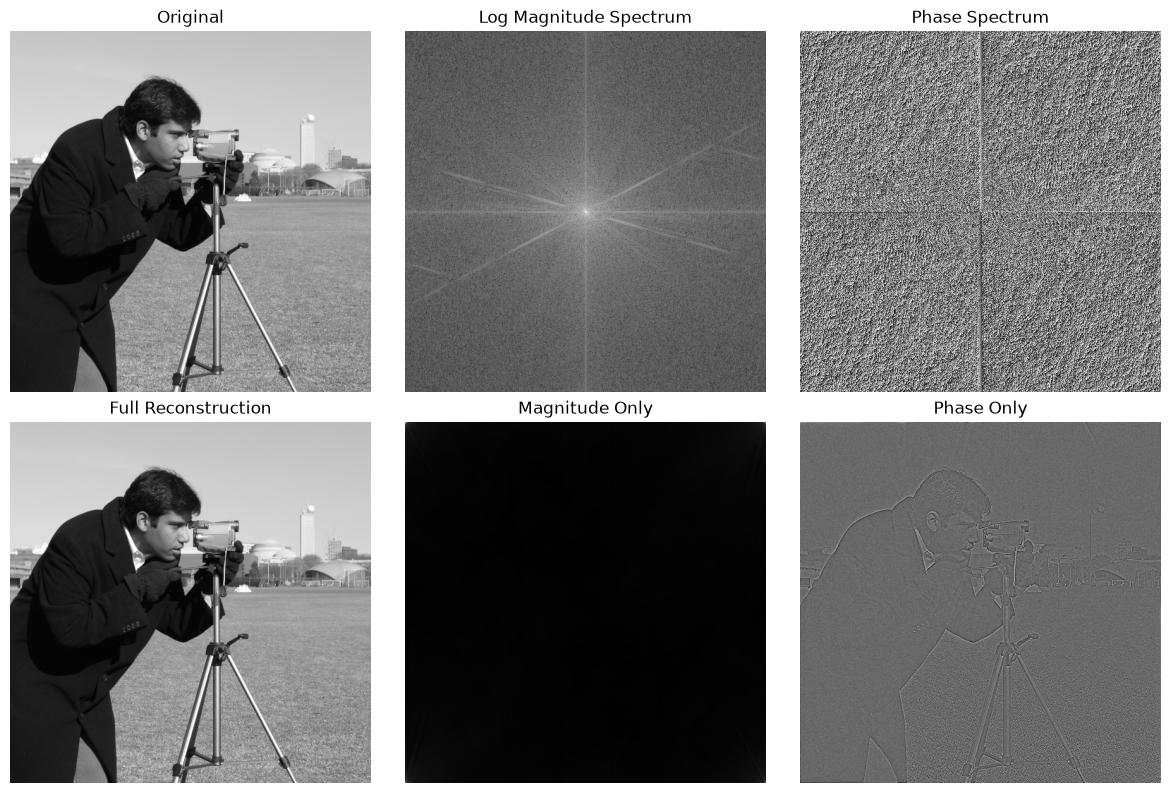

In [2]:
from skimage import data
import numpy as np
import matplotlib.pyplot as plt

img = data.camera().astype(float)

F = np.fft.fft2(img)
magnitude = np.abs(F)
phase = np.angle(F)

# Inverse transformations
reconstructed = np.fft.ifft2(F).real
magnitude_only = np.fft.ifft2(magnitude).real
phase_only = np.fft.ifft2(np.exp(1j * phase)).real

images = [
    img,
    np.log1p(np.abs(np.fft.fftshift(F))),
    np.fft.fftshift(phase),
    reconstructed,
    magnitude_only,
    phase_only
]

titles = [
    "Original",
    "Log Magnitude Spectrum",
    "Phase Spectrum",
    "Full Reconstruction",
    "Magnitude Only",
    "Phase Only"
]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, image, title in zip(axes.flat, images, titles):
    ax.imshow(image, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 3: FREQUENCY CENTERING

Objective: Examine how fftshift rearranges the Fourier spectrum.

Tasks:
 1. Compute the Fourier transform of an image.
 2. Compare centered and uncentered magnitude spectra.
 3. Apply logarithmic scaling to reveal weak frequency components.

Question: Why is the DC component moved to the center for visualization?


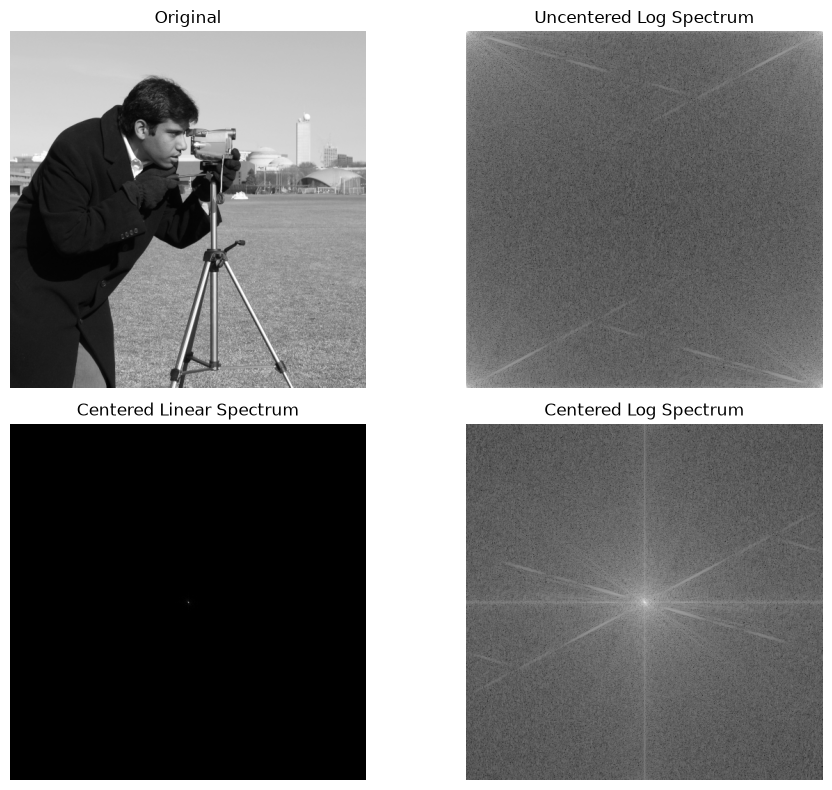

In [3]:
from skimage import data
import numpy as np
import matplotlib.pyplot as plt

img = data.camera().astype(float)

F = np.fft.fft2(img)
F_centered = np.fft.fftshift(F)

images = [
    img,
    np.log1p(np.abs(F)),
    np.abs(F_centered),
    np.log1p(np.abs(F_centered))
]

titles = [
    "Original",
    "Uncentered Log Spectrum",
    "Centered Linear Spectrum",
    "Centered Log Spectrum"
]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for ax, image, title in zip(axes.flat, images, titles):
    ax.imshow(image, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 4: IDEAL LOW-PASS FILTERING

Objective: Investigate the effect of cutoff frequency on image smoothing.

Tasks:
 1. Construct circular ideal low-pass filters.
 2. Apply cutoff radii of 8, 16, 32, 64, and 128.
 3. Compare each filter mask with its resulting image.

Question: How does cutoff frequency affect blurring and ringing?

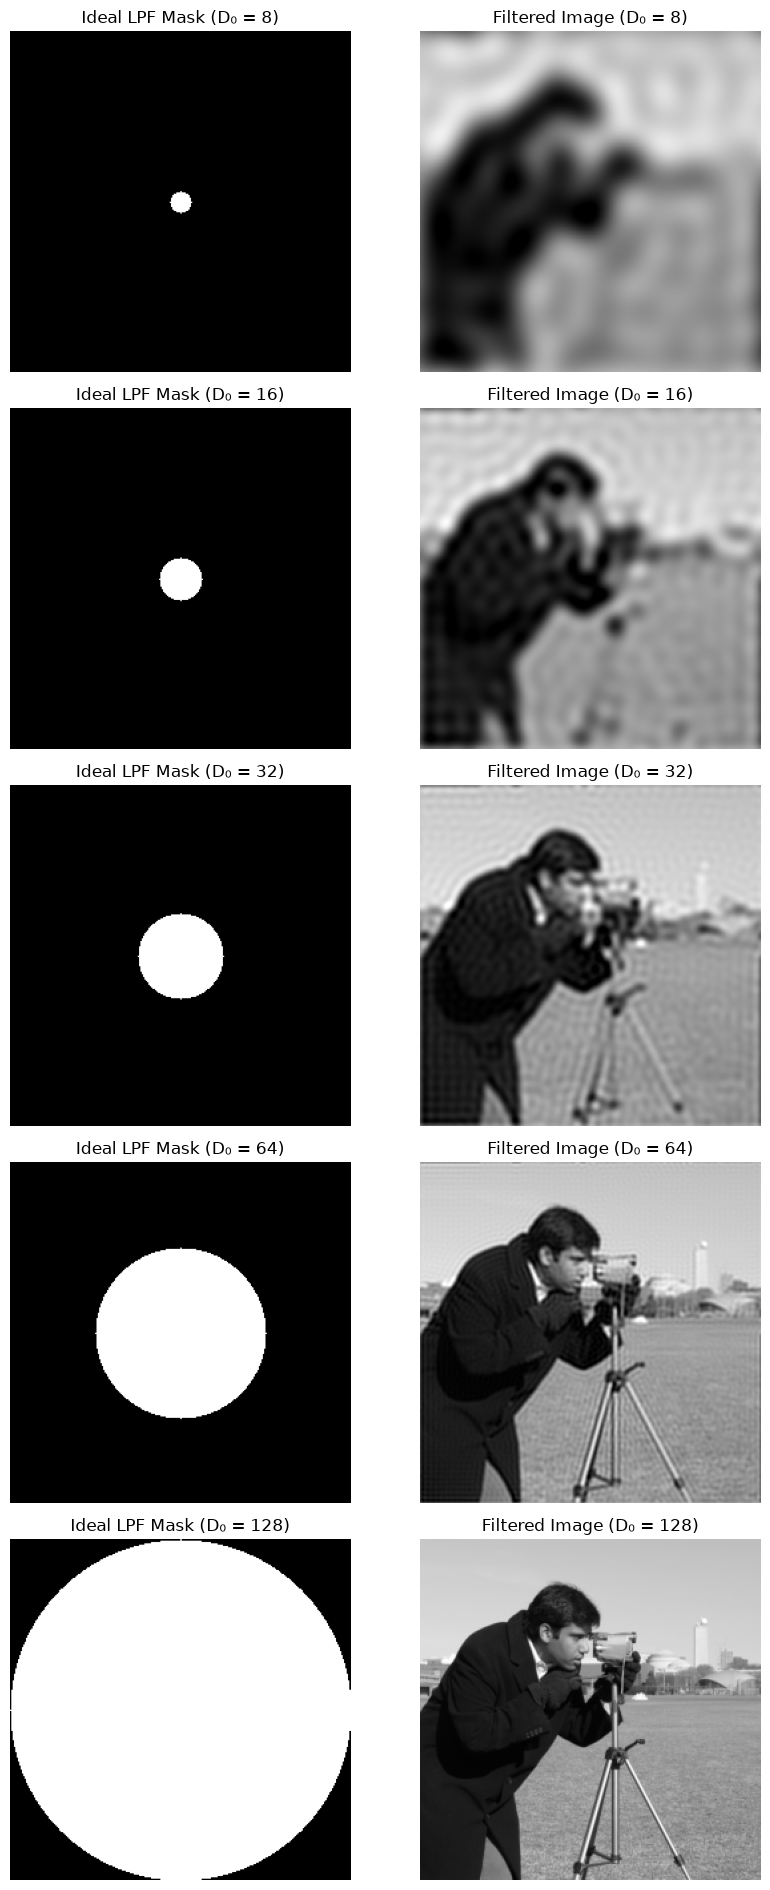

In [4]:
from skimage import data, transform
import numpy as np
import matplotlib.pyplot as plt

img = transform.resize(
    data.camera(), (256, 256),
    preserve_range=True, anti_aliasing=True
)

F = np.fft.fftshift(np.fft.fft2(img))

M, N = img.shape
Y, X = np.indices((M, N))
D = np.sqrt((Y - M//2)**2 + (X - N//2)**2)

cutoffs = [8, 16, 32, 64, 128]

fig, axes = plt.subplots(5, 2, figsize=(9, 19))

for i, D0 in enumerate(cutoffs):
    # Ideal low-pass filter
    H = (D <= D0).astype(float)

    # Frequency-domain filtering
    G = F * H
    filtered = np.fft.ifft2(np.fft.ifftshift(G)).real

    # Filter mask (left)
    axes[i, 0].imshow(H, cmap="gray", vmin=0, vmax=1)
    axes[i, 0].set_title(f"Ideal LPF Mask (D₀ = {D0})")
    axes[i, 0].axis("off")

    # Filtered image (right)
    axes[i, 1].imshow(filtered, cmap="gray", vmin=0, vmax=255)
    axes[i, 1].set_title(f"Filtered Image (D₀ = {D0})")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 5: COMPARISON OF LOW-PASS FILTERS

Objective: Compare Ideal, Gaussian, and Butterworth LPFs.

Tasks:
 1. Construct three frequency-domain filters.
 2. Apply the same characteristic cutoff parameter D0.
 3. Compare transfer functions, filtered spectra, and images.

Question: Which filter produces the strongest ringing, and why?

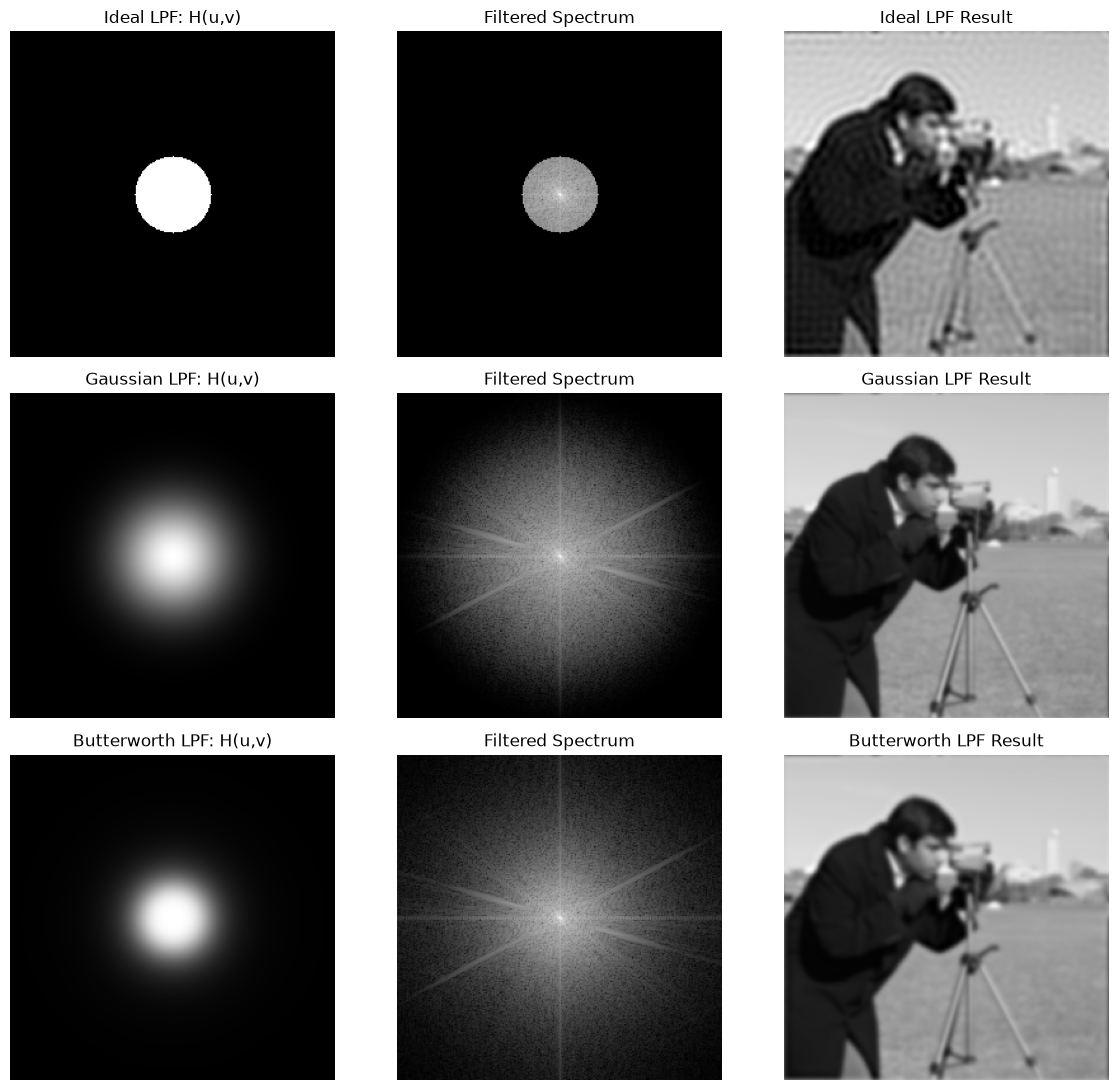

In [5]:
from skimage import data, transform
import numpy as np
import matplotlib.pyplot as plt

img = transform.resize(
    data.camera(), (256, 256),
    preserve_range=True, anti_aliasing=True
)

F = np.fft.fftshift(np.fft.fft2(img))

M, N = img.shape
Y, X = np.indices((M, N))
D = np.sqrt((Y - M//2)**2 + (X - N//2)**2)

D0 = 30
n = 2

filters = {
    "Ideal": (D <= D0).astype(float),
    "Gaussian": np.exp(-(D**2) / (2 * D0**2)),
    "Butterworth": 1 / (1 + (D / D0)**(2*n))
}

fig, axes = plt.subplots(3, 3, figsize=(12, 11))

for i, (name, H) in enumerate(filters.items()):
    G = F * H
    filtered = np.fft.ifft2(np.fft.ifftshift(G)).real

    axes[i, 0].imshow(H, cmap="gray", vmin=0, vmax=1)
    axes[i, 0].set_title(f"{name} LPF: H(u,v)")

    axes[i, 1].imshow(np.log1p(np.abs(G)), cmap="gray")
    axes[i, 1].set_title("Filtered Spectrum")

    axes[i, 2].imshow(filtered, cmap="gray", vmin=0, vmax=255)
    axes[i, 2].set_title(f"{name} LPF Result")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 6: HIGH-PASS FILTERING

Objective: Compare Ideal, Gaussian, and Butterworth HPFs.

Tasks:
 1. Construct HPFs from their corresponding LPFs.
 2. Examine their frequency responses.
 3. Compare their effects on edges and fine details.

Question: Why do high-pass filtered images lose their average brightness?

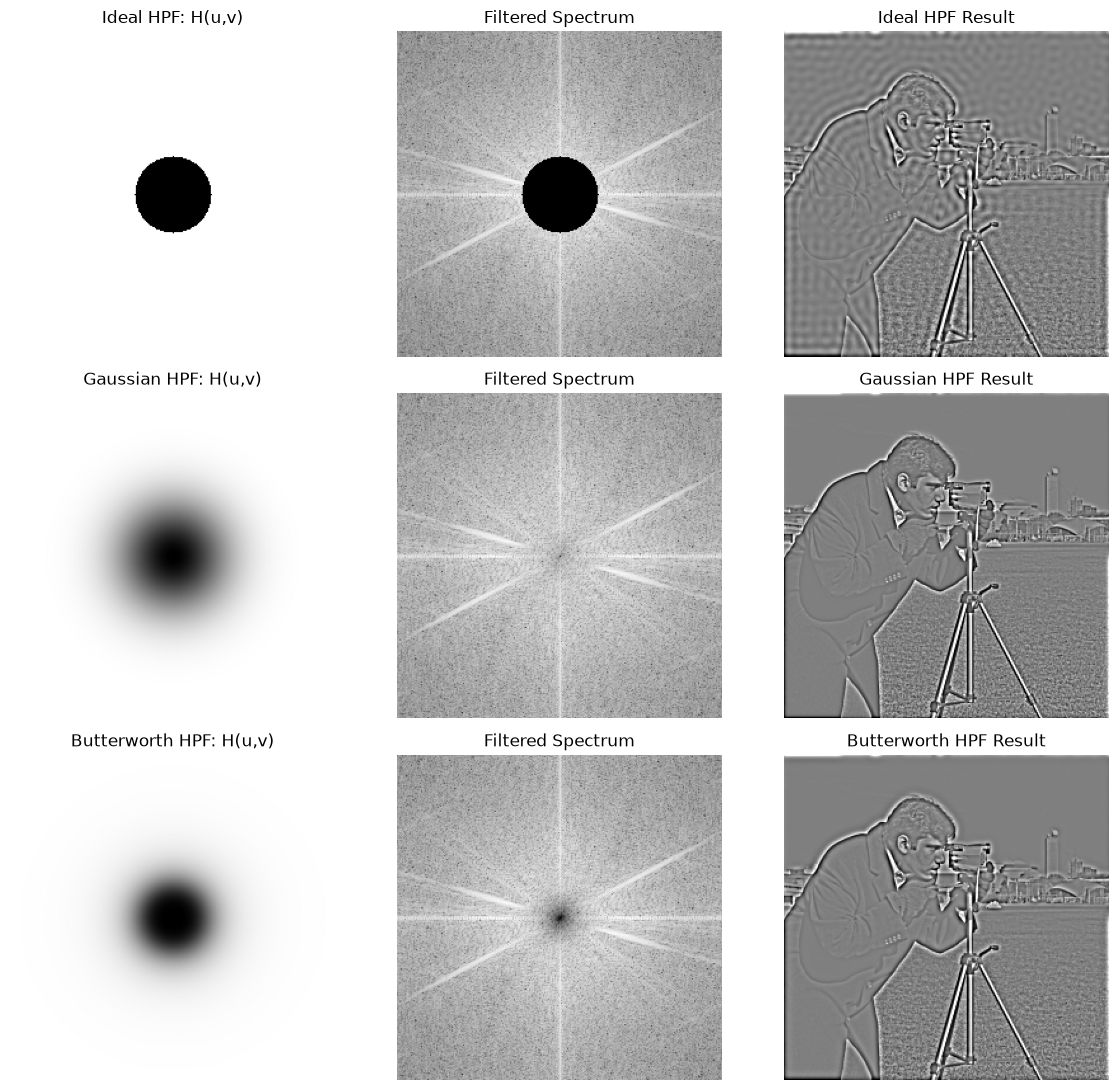

In [6]:
from skimage import data, transform
import numpy as np
import matplotlib.pyplot as plt

img = transform.resize(
    data.camera(), (256, 256),
    preserve_range=True, anti_aliasing=True
)

F = np.fft.fftshift(np.fft.fft2(img))

M, N = img.shape
Y, X = np.indices((M, N))
D = np.sqrt((Y - M//2)**2 + (X - N//2)**2)

D0 = 30
n = 2

lpfs = {
    "Ideal": (D <= D0).astype(float),
    "Gaussian": np.exp(-D**2 / (2 * D0**2)),
    "Butterworth": 1 / (1 + (D / D0)**(2*n))
}

fig, axes = plt.subplots(3, 3, figsize=(12, 11))

for i, (name, LPF) in enumerate(lpfs.items()):
    H = 1 - LPF
    G = F * H

    filtered = np.fft.ifft2(np.fft.ifftshift(G)).real

    axes[i, 0].imshow(H, cmap="gray", vmin=0, vmax=1)
    axes[i, 0].set_title(f"{name} HPF: H(u,v)")

    axes[i, 1].imshow(np.log1p(np.abs(G)), cmap="gray")
    axes[i, 1].set_title("Filtered Spectrum")

    # Display signed high-pass response around zero
    limit = max(np.percentile(np.abs(filtered), 99), 1e-12)
    axes[i, 2].imshow(
        filtered, cmap="gray",
        vmin=-limit, vmax=limit
    )
    axes[i, 2].set_title(f"{name} HPF Result")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 7: HIGH-FREQUENCY EMPHASIS

Objective: Enhance fine details while retaining low-frequency information.

Tasks:
 1. Construct a Butterworth high-pass filter.
 2. Apply ordinary high-pass filtering.
 3. Apply high-frequency emphasis with a=0.5 and b=1.
 4. Compare the results.

Question: Why is high-frequency emphasis more useful for visual enhancement?


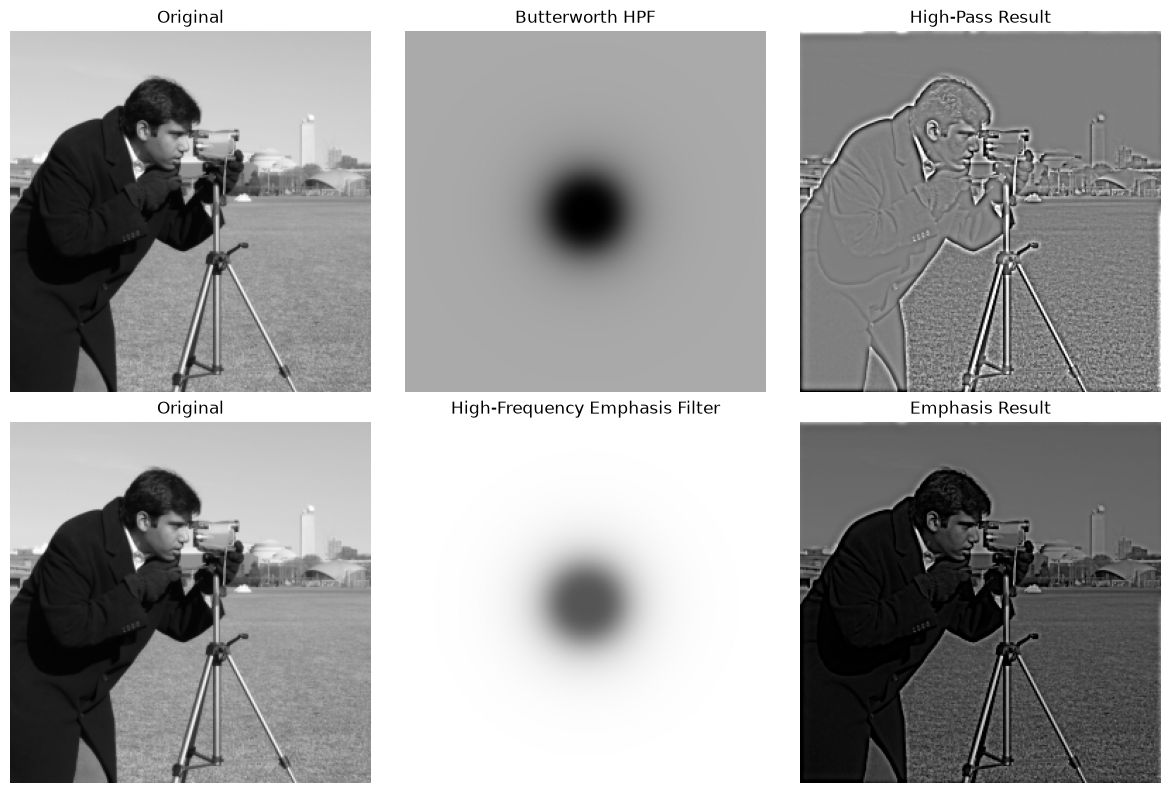

In [7]:
from skimage import data, transform
import numpy as np
import matplotlib.pyplot as plt

img = transform.resize(
    data.camera(), (256, 256),
    preserve_range=True, anti_aliasing=True
)

F = np.fft.fftshift(np.fft.fft2(img))

M, N = img.shape
Y, X = np.indices((M, N))
D = np.sqrt((Y - M//2)**2 + (X - N//2)**2)

D0, n = 30, 2
a, b = 0.5, 1.0

LPF = 1 / (1 + (D / D0)**(2*n))
HPF = 1 - LPF

H_emphasis = a + b * HPF

high_pass = np.fft.ifft2(
    np.fft.ifftshift(F * HPF)
).real

emphasized = np.fft.ifft2(
    np.fft.ifftshift(F * H_emphasis)
).real

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

images = [
    img,
    HPF,
    high_pass,
    img,
    H_emphasis,
    emphasized
]

titles = [
    "Original",
    "Butterworth HPF",
    "High-Pass Result",
    "Original",
    "High-Frequency Emphasis Filter",
    "Emphasis Result"
]

for ax, image, title in zip(axes.flat, images, titles):
    if "Filter" in title or title == "Butterworth HPF":
        ax.imshow(image, cmap="gray", vmin=0, vmax=1.5)
    elif title == "High-Pass Result":
        limit = max(np.percentile(np.abs(image), 99), 1e-12)
        ax.imshow(image, cmap="gray", vmin=-limit, vmax=limit)
    else:
        ax.imshow(image, cmap="gray", vmin=0, vmax=255)

    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 8: SPATIAL VS FREQUENCY-DOMAIN FILTERING

Objective: Verify the convolution theorem numerically.

Tasks:
 1. Construct a Gaussian smoothing kernel.
 2. Filter an image using spatial convolution.
 3. Perform equivalent linear convolution using FFT.
 4. Measure the numerical difference.

Question: Why is padding important for FFT-based convolution?


Maximum absolute difference: 2.5579538487363607e-13
Mean absolute difference: 3.893981559183364e-14
Results match: True


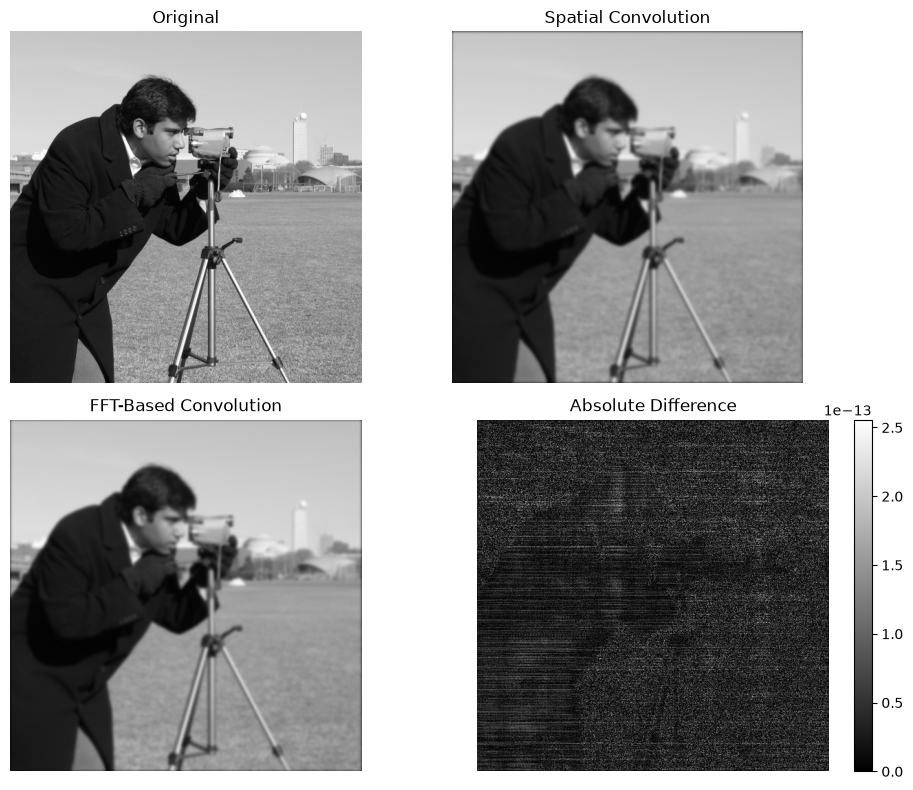

In [8]:
from skimage import data
from scipy.signal import convolve2d, fftconvolve
import numpy as np
import matplotlib.pyplot as plt

img = data.camera().astype(float)

# Construct a normalized 2D Gaussian kernel
sigma = 2
radius = 3 * sigma

x = np.arange(-radius, radius + 1)
X, Y = np.meshgrid(x, x)

kernel = np.exp(-(X**2 + Y**2) / (2 * sigma**2))
kernel /= kernel.sum()

# Both methods compute linear convolution with zero-padded boundaries
spatial = convolve2d(
    img, kernel, mode="same", boundary="fill"
)

frequency = fftconvolve(img, kernel, mode="same")

difference = np.abs(spatial - frequency)

print("Maximum absolute difference:", difference.max())
print("Mean absolute difference:", difference.mean())
print("Results match:", np.allclose(spatial, frequency, atol=1e-8))

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

images = [img, spatial, frequency, difference]
titles = [
    "Original",
    "Spatial Convolution",
    "FFT-Based Convolution",
    "Absolute Difference"
]

for ax, image, title in zip(axes.flat, images, titles):
    if title == "Absolute Difference":
        im = ax.imshow(image, cmap="gray")
        fig.colorbar(im, ax=ax, fraction=0.046)
    else:
        ax.imshow(image, cmap="gray", vmin=0, vmax=255)

    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()